### Classification Baseline Models: Logistic Regression | Linear SVM | XGBoost

**Question:** Can we predict AI Bill status (Pending, Pass, Fail) based on legislative database including bill text and metadata?<br/>
**Approach:** Train 3 baseline models to understand overall classification performance on 3 subsets of the data. <br/><br/>
**Data Subsets:**
- Metadata Only models<br/>
- Metadata + NCSL_Summary_clean<br/>
- Metadata + Bill_Text_clean<br/>



In [1]:
import sys
from pathlib import Path

root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(root)) # so the notebook can import src/topic_analysis.py

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    LabelEncoder
)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,

)

from xgboost import XGBClassifier

from src.topic_analysis import LEGAL_STOPWORDS

In [ ]:
## Stop words
#List created from topic analysis
legal_stop_words = sorted(LEGAL_STOPWORDS.keys())
#List of English stop words from sklearn and legal stop words from topic analysis
english_legal_stop_words = sorted(set(ENGLISH_STOP_WORDS) | LEGAL_STOPWORDS.keys())

In [2]:
## Common data loading 

common = pd.read_csv(r"C:\Users\david\OneDrive\UofM\siads-josue\data\processed\common_intake\common_records.csv")

common.info()

<class 'pandas.DataFrame'>
RangeIndex: 2567 entries, 0 to 2566
Data columns (total 45 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Bill_Number                    2567 non-null   str    
 1   measure_code                   2567 non-null   str    
 2   Bill_Title                     2535 non-null   str    
 3   Jurisdiction                   2567 non-null   str    
 4   NCSL_Summary                   2567 non-null   str    
 5   NCSL_Category                  2329 non-null   str    
 6   Bill_URL                       2567 non-null   str    
 7   Version_Date                   2567 non-null   str    
 8   Year                           2567 non-null   int64  
 9   Bill_Status                    2567 non-null   str    
 10  State_Political_Control        2565 non-null   str    
 11  Regional_Cluster_ID            2567 non-null   str    
 12  Bill_Text                      2567 non-null   str    
 13 

### Train - Validate - Test Split

In [3]:
## Introduction Year formatting for data split based on this date. 

common["Introduction_Date"] = pd.to_datetime(
    common["Introduction_Date"], errors="coerce"
)

common['introduction_year'] = common['Introduction_Date'].dt.year

In [4]:
train_df = common[common["introduction_year"].between(2019, 2024)].copy()
val_df = common[common["introduction_year"] == 2025].copy()
test_df = common[common["introduction_year"] == 2026].copy()

for name, subset in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{name}: {len(subset)} bills")

    print(
        subset["Bill_Status_Grouped"]
        .value_counts(normalize=True)
        .mul(100)
        .round(1)
    )


Train: 722 bills
Bill_Status_Grouped
Failed     45.3
Pending    41.4
Passed     13.3
Name: proportion, dtype: float64

Validation: 1016 bills
Bill_Status_Grouped
Pending    54.1
Failed     27.7
Passed     18.2
Name: proportion, dtype: float64

Test: 828 bills
Bill_Status_Grouped
Pending    76.2
Failed     18.8
Passed      5.0
Name: proportion, dtype: float64


#### Dataset configs for all models

In [5]:
# Sets of categorical and numeric features for metadata based models.
categorical_features = [
    "measure_code",
    "Jurisdiction",
    "State_Political_Control"
]

numeric_features = [
    "D_Count",
    "R_Count",
    "Other_Count",
    "Unknown_Count",
    "Total_Sponsors"
]

ratio_features = [
    "Democrat_Sponsor_Ratio",
    "Republican_Sponsor_Ratio"
]

binary_features = [
    "Bipartisan_Support"
]

metadata_features = categorical_features + numeric_features + ratio_features + binary_features

TARGET = "Bill_Status_Grouped"
RANDOM_STATE = 42



In [6]:
## Review numeric features before preprocessing pipeline is built. 

missing_audit = pd.DataFrame({
    "Missing": train_df[numeric_features].isna().sum(),
    "Zeros": train_df[numeric_features].eq(0).sum(),
    "Median": train_df[numeric_features].median()
})

display(missing_audit)

,Missing,Zeros,Median
D_Count,0,206,1.0
R_Count,0,398,0.0
Other_Count,0,710,0.0
Unknown_Count,0,652,0.0
Total_Sponsors,0,0,2.0


### Logistic Regression

In [7]:
X_train_meta = train_df[metadata_features].copy()
X_val_meta = val_df[metadata_features].copy()

y_train = train_df[TARGET].copy()
y_val = val_df[TARGET].copy()

In [10]:
### Transformers used for preprocessing across models

# Categorical preprocessing
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value=0,
        add_indicator=True
    )),
    ("scaler", StandardScaler())
])

#Ratio preprocessing
ratio_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value=0,
        add_indicator=True
    )),
    ("scaler", StandardScaler())
])

# Binary preprocessing
binary_transformer = SimpleImputer(
    strategy="most_frequent"
)

# Text preprocessing
text_transformer = TfidfVectorizer(
             max_features=5000,
             ngram_range=(1, 2),
             min_df=2,
             max_df=0.95,
             sublinear_tf=True,
             stop_words=legal_stop_words 
         )

In [11]:
# Combine transformations
metadata_preprocessor = ColumnTransformer(
    transformers=[
        ("categorical",
         categorical_transformer,
         categorical_features),
        ("numeric",
         numeric_transformer,
         numeric_features),
        ("ratio",
         ratio_transformer,
            ratio_features),
        ("binary",
         binary_transformer,
            binary_features)    
    ]
)

In [12]:
# Fit only on training data
X_train_meta_processed = metadata_preprocessor.fit_transform(
    X_train_meta
)

X_val_meta_processed = metadata_preprocessor.transform(
    X_val_meta
)

In [13]:


lr_metadata = LogisticRegression(
    C=1.0,
    l1_ratio=0, # Per documentation, penalty='l2' is the default when l1_ratio=0, so this is equivalent to L2 regularization
    solver="lbfgs",
    class_weight=None,
    max_iter=2000,
    random_state=RANDOM_STATE
)

lr_metadata.fit(
    X_train_meta_processed,
    y_train
)

X_train_meta_pred = lr_metadata.predict(
    X_train_meta_processed
)

y_val_meta_pred = lr_metadata.predict(
    X_val_meta_processed
)


              precision    recall  f1-score   support

      Failed       0.42      0.87      0.57       281
      Passed       0.29      0.08      0.13       185
     Pending       0.95      0.66      0.78       550

    accuracy                           0.61      1016
   macro avg       0.55      0.54      0.49      1016
weighted avg       0.68      0.61      0.60      1016

Macro F1: 0.4902989532811397
Balanced Accuracy: 0.5370496734197802


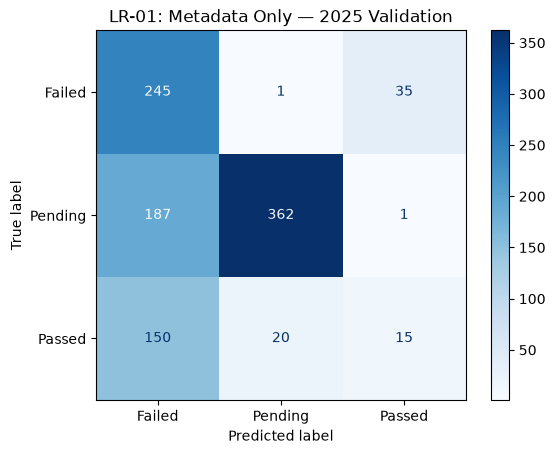

In [14]:
print(classification_report(
    y_val,
    y_val_meta_pred,
    zero_division=0
))

print(
    "Macro F1:",
    f1_score(y_val, y_val_meta_pred, average="macro")
)

print(
    "Balanced Accuracy:",
    balanced_accuracy_score(y_val, y_val_meta_pred)
)

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_meta_pred,
    labels=["Failed", "Pending", "Passed"],
    cmap="Blues"
)

plt.title("LR-01: Metadata Only — 2025 Validation")
plt.show()


#### NCSL Summary + Metadata Model

In [15]:
meta_summary_preprocessor = ColumnTransformer(
    transformers=[
        ("text",
         text_transformer,
         "NCSL_Summary_clean"),

        ("categorical",
         categorical_transformer,
         categorical_features),

        ("numeric",
         numeric_transformer,
         numeric_features),

        ("ratio",
         ratio_transformer,
            ratio_features),

        ("binary",
         binary_transformer,
            binary_features)
    ],
    sparse_threshold=1.0
)


In [16]:
X_train_meta_summary = train_df[
    ["NCSL_Summary_clean"] + metadata_features
].copy()

X_val_meta_summary = val_df[
    ["NCSL_Summary_clean"] + metadata_features
].copy()

In [17]:
# Fit the combined preprocessor on the training data and transform both training and validation data
X_train_meta_summary_processed = (
    meta_summary_preprocessor.fit_transform(X_train_meta_summary)
)

X_val_meta_summary_processed = (
    meta_summary_preprocessor.transform(X_val_meta_summary)
)

In [18]:
# Fit the logistic regression model
lr_meta_summary = LogisticRegression(
    C=1.0,
    l1_ratio=0, # Per documentation, penalty='l2' is the default when l1_ratio=0, so this is equivalent to L2 regularization
    solver="lbfgs",
    class_weight=None,
    max_iter=2000,
    random_state=RANDOM_STATE
)

lr_meta_summary.fit(
    X_train_meta_summary_processed,
    y_train
)

X_train_meta_summary_pred = lr_meta_summary.predict(
    X_train_meta_summary_processed
)

y_val_meta_summary_pred = lr_meta_summary.predict(
    X_val_meta_summary_processed
)

              precision    recall  f1-score   support

      Failed       0.43      0.92      0.59       281
      Passed       0.47      0.08      0.14       185
     Pending       0.93      0.64      0.76       550

    accuracy                           0.62      1016
   macro avg       0.61      0.55      0.49      1016
weighted avg       0.71      0.62      0.60      1016

Macro F1: 0.49489810290055686
Balanced Accuracy: 0.5488085432569418


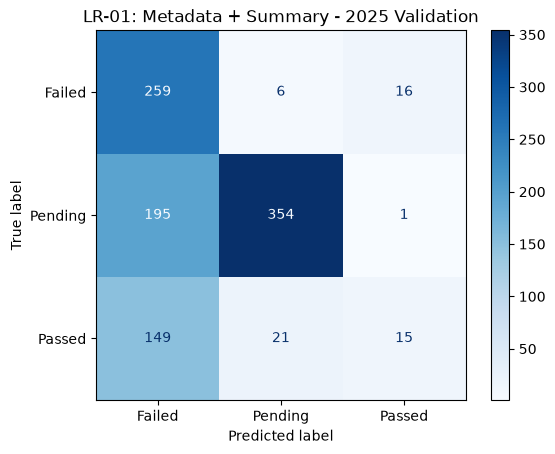

In [19]:
# Evaluate the model
print(classification_report(
    y_val,
    y_val_meta_summary_pred,
    zero_division=0
))

print(
    "Macro F1:",
    f1_score(y_val, y_val_meta_summary_pred, average="macro")
)

print(
    "Balanced Accuracy:",
    balanced_accuracy_score(y_val, y_val_meta_summary_pred)
)

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_meta_summary_pred,
    labels=["Failed", "Pending", "Passed"],
    cmap="Blues"
)

plt.title("LR-01: Metadata + Summary - 2025 Validation")
plt.show()

#### Bill Text + Metadata Model

In [20]:
meta_text_preprocessor = ColumnTransformer(
    transformers=[
        ("text",
         text_transformer,
         "Bill_Text_clean"),

        ("categorical",
         categorical_transformer,
         categorical_features),

        ("numeric",
         numeric_transformer,
         numeric_features),

        ("ratio",
         ratio_transformer,
            ratio_features),

        ("binary",
         binary_transformer,
            binary_features)
    ],
    sparse_threshold=1.0
)

In [21]:
X_train_meta_text = train_df[
    ["Bill_Text_clean"] + metadata_features
].copy()

X_val_meta_text = val_df[
    ["Bill_Text_clean"] + metadata_features
].copy()

In [22]:
X_train_meta_text_processed = (
    meta_text_preprocessor.fit_transform(X_train_meta_text)
)

X_val_meta_text_processed = (
    meta_text_preprocessor.transform(X_val_meta_text)
)

In [23]:
lr_meta_text = LogisticRegression(
    C=1.0,
    l1_ratio=0,# Per documentation, penalty='l2' is the default when l1_ratio=0, so this is equivalent to L2 regularization
    solver="lbfgs",
    class_weight=None,
    max_iter=2000,
    random_state=RANDOM_STATE
)

lr_meta_text.fit(
    X_train_meta_text_processed,
    y_train
)

X_train_meta_text_pred = lr_meta_text.predict(
    X_train_meta_text_processed
)
y_val_meta_text_pred = lr_meta_text.predict(
    X_val_meta_text_processed
)



              precision    recall  f1-score   support

      Failed       0.43      0.90      0.59       281
      Passed       0.41      0.08      0.14       185
     Pending       0.93      0.66      0.77       550

    accuracy                           0.62      1016
   macro avg       0.59      0.55      0.50      1016
weighted avg       0.69      0.62      0.60      1016

Macro F1: 0.49702974276633616
Balanced Accuracy: 0.5483318906094707


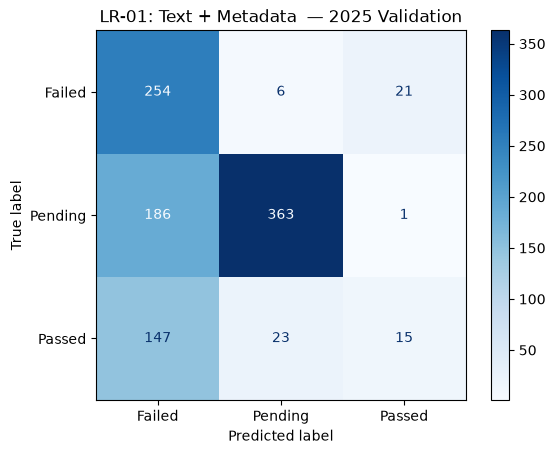

In [24]:
print(classification_report(
    y_val,
    y_val_meta_text_pred,
    zero_division=0
))

print(
    "Macro F1:",
    f1_score(y_val, y_val_meta_text_pred, average="macro")
)

print(
    "Balanced Accuracy:",
    balanced_accuracy_score(y_val, y_val_meta_text_pred)
)

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_val_meta_text_pred,
    labels=["Failed", "Pending", "Passed"],
    cmap="Blues"
)

plt.title("LR-01: Text + Metadata  — 2025 Validation")
plt.show()

Full text does not seem to be adding a significant amount of importance compared to NCSL summaries or metadata. 

### SVM Models

Metadata Only model

In [25]:
svm_meta_preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", 
        categorical_transformer,
        categorical_features),

        ("numeric", 
        numeric_transformer,
        numeric_features),
        ("ratio",
        ratio_transformer,
        ratio_features
        ),
        ("binary",
        binary_transformer,
        binary_features
        )

    ],
    remainder="drop",
    sparse_threshold=1.0
)


In [26]:

svm_meta = LinearSVC(
    C=1.0,
    penalty="l2",
    loss="squared_hinge",
    dual="auto",
    class_weight=None,
    max_iter=5000,
    random_state=RANDOM_STATE
)

svm_meta_pipeline = Pipeline([
    ("preprocessor", svm_meta_preprocessor),
    ("classifier", svm_meta)
])


In [27]:
svm_meta_pipeline.fit(X_train_meta, y_train)

svm_train_meta_pred = svm_meta_pipeline.predict(X_train_meta)
svm_val_meta_pred = svm_meta_pipeline.predict(X_val_meta)

print("SVM — Training Performance")
print(classification_report(
    y_train,
    svm_train_meta_pred,
    zero_division=0
))

print("\nSVM — Validation Performance")
print(classification_report(
    y_val,
    svm_val_meta_pred,
    zero_division=0
))

SVM — Training Performance
              precision    recall  f1-score   support

      Failed       0.82      0.80      0.81       327
      Passed       0.79      0.28      0.42        96
     Pending       0.78      0.97      0.87       299

    accuracy                           0.80       722
   macro avg       0.80      0.68      0.70       722
weighted avg       0.80      0.80      0.78       722


SVM — Validation Performance
              precision    recall  f1-score   support

      Failed       0.43      0.82      0.57       281
      Passed       0.40      0.19      0.26       185
     Pending       0.95      0.68      0.79       550

    accuracy                           0.63      1016
   macro avg       0.59      0.56      0.54      1016
weighted avg       0.71      0.63      0.63      1016



In [28]:
svm_results = {
    "Model": "Linear SVM",
    "Feature_Set": "Metadata Only",
    "Train_Macro_F1": f1_score(
        y_train, svm_train_meta_pred, average="macro"
    ),
    "Val_Macro_F1": f1_score(
        y_val, svm_val_meta_pred, average="macro"
    ),
    "Val_Weighted_F1": f1_score(
        y_val, svm_val_meta_pred, average="weighted"
    ),
    "Val_Balanced_Accuracy": balanced_accuracy_score(
        y_val, svm_val_meta_pred
    )
}

pd.Series(svm_results)


Model                       Linear SVM
Feature_Set              Metadata Only
Train_Macro_F1                  0.6982
Val_Macro_F1                  0.539292
Val_Weighted_F1               0.633277
Val_Balanced_Accuracy         0.564357
dtype: object

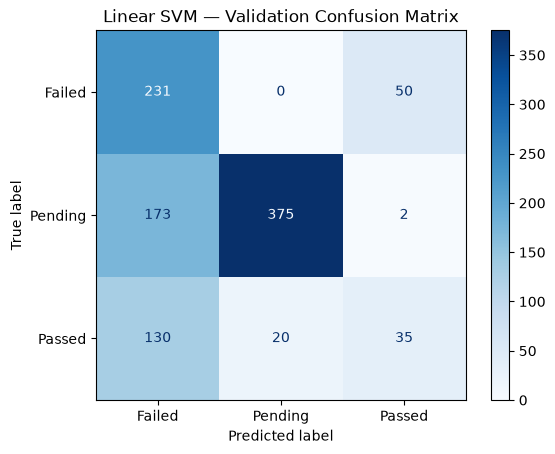

In [29]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    svm_val_meta_pred,
    labels=["Failed", "Pending", "Passed"],
    cmap="Blues",
    values_format="d"
)

plt.title("Linear SVM — Validation Confusion Matrix")
plt.show()

In [31]:

svm_feature_names = (
    svm_meta_pipeline.named_steps["preprocessor"]
    .get_feature_names_out()
)

svm_classifier = (
    svm_meta_pipeline.named_steps["classifier"]
)

svm_coefficients = pd.DataFrame(
    svm_classifier.coef_,
    index=svm_classifier.classes_,
    columns=svm_feature_names
)

# Features with the largest positive coefficients for Passed
svm_coefficients.loc["Passed"].nlargest(15)

categorical__Jurisdiction_Oregon           1.246380
categorical__Jurisdiction_Utah             1.207433
categorical__Jurisdiction_Arkansas         1.159495
categorical__measure_code_HR               1.036795
categorical__Jurisdiction_Alabama          0.931094
categorical__measure_code_AR               0.888817
categorical__Jurisdiction_Wisconsin        0.799842
categorical__Jurisdiction_Colorado         0.687126
categorical__measure_code_SJR              0.410720
categorical__Jurisdiction_New Hampshire    0.301802
categorical__Jurisdiction_Delaware         0.282822
categorical__Jurisdiction_Connecticut      0.275603
categorical__measure_code_HCR              0.270951
binary__Bipartisan_Support                 0.253947
categorical__Jurisdiction_Virginia         0.249466
Name: Passed, dtype: float64

Metadata + NCSL Nummary

In [32]:
svm_meta_summary_preprocessor = ColumnTransformer(
    transformers=[
        ("text",
        text_transformer,
        "NCSL_Summary_clean"),
        ("categorical", 
        categorical_transformer,
        categorical_features),
        ("numeric", 
        numeric_transformer,
        numeric_features),
        ("ratio",
        ratio_transformer,
        ratio_features),
        ("binary",
        binary_transformer,
        binary_features)

    ],
    remainder="drop",
    sparse_threshold=1.0
)



In [33]:
svm_meta_summary = LinearSVC(
    C=1.0,
    penalty="l2",
    loss="squared_hinge",
    dual="auto",
    class_weight=None,
    max_iter=5000,
    random_state=RANDOM_STATE
)

svm__meta_summary_pipeline = Pipeline([
    ("preprocessor", svm_meta_summary_preprocessor),
    ("classifier", svm_meta_summary)
])

In [34]:
svm__meta_summary_pipeline.fit(X_train_meta_summary, y_train)

svm_train_meta_sum_pred = svm__meta_summary_pipeline.predict(X_train_meta_summary)
svm_val_meta_sum_pred = svm__meta_summary_pipeline.predict(X_val_meta_summary)

print("SVM — Training Performance")
print(classification_report(
    y_train,
    svm_train_meta_sum_pred,
    zero_division=0
))

print("\nSVM — Validation Performance")
print(classification_report(
    y_val,
    svm_val_meta_sum_pred,
    zero_division=0
))

SVM — Training Performance
              precision    recall  f1-score   support

      Failed       0.98      0.97      0.98       327
      Passed       0.99      0.95      0.97        96
     Pending       0.97      1.00      0.99       299

    accuracy                           0.98       722
   macro avg       0.98      0.97      0.98       722
weighted avg       0.98      0.98      0.98       722


SVM — Validation Performance
              precision    recall  f1-score   support

      Failed       0.44      0.85      0.58       281
      Passed       0.48      0.22      0.30       185
     Pending       0.94      0.65      0.77       550

    accuracy                           0.63      1016
   macro avg       0.62      0.58      0.55      1016
weighted avg       0.72      0.63      0.63      1016



In [35]:
svm_meta_sum_results = {
    "Model": "Linear SVM",
    "Feature_Set": "Metadata + Summary",
    "Train_Macro_F1": f1_score(
        y_train, svm_train_meta_sum_pred, average="macro"
    ),
    "Val_Macro_F1": f1_score(
        y_val, svm_val_meta_sum_pred, average="macro"
    ),
    "Val_Weighted_F1": f1_score(
        y_val, svm_val_meta_sum_pred, average="weighted"
    ),
    "Val_Balanced_Accuracy": balanced_accuracy_score(
        y_val, svm_val_meta_sum_pred
    )
}

pd.Series(svm_meta_sum_results)

Model                            Linear SVM
Feature_Set              Metadata + Summary
Train_Macro_F1                     0.976723
Val_Macro_F1                       0.550758
Val_Weighted_F1                    0.632033
Val_Balanced_Accuracy              0.576147
dtype: object

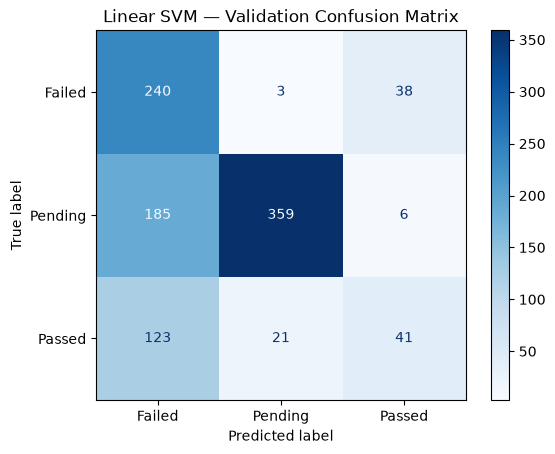

In [36]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    svm_val_meta_sum_pred,
    labels=["Failed", "Pending", "Passed"],
    cmap="Blues",
    values_format="d"
)

plt.title("Linear SVM — Validation Confusion Matrix")
plt.show()

In [37]:

svm_feature_names = (
    svm__meta_summary_pipeline.named_steps["preprocessor"]
    .get_feature_names_out()
)

svm_classifier = (
    svm__meta_summary_pipeline.named_steps["classifier"]
)

svm_coefficients = pd.DataFrame(
    svm_classifier.coef_,
    index=svm_classifier.classes_,
    columns=svm_feature_names
)

# Features with the largest positive coefficients for Passed
svm_coefficients.loc["Passed"].nlargest(15)

categorical__Jurisdiction_Utah        1.068885
categorical__measure_code_HR          0.949847
categorical__Jurisdiction_Oregon      0.938806
text__criminal penalties              0.836774
categorical__Jurisdiction_Colorado    0.751359
categorical__Jurisdiction_Arkansas    0.745474
categorical__Jurisdiction_Alabama     0.690976
text__to the                          0.680052
text__certain                         0.666682
text__by artificial                   0.666433
text__shall                           0.662844
categorical__measure_code_AR          0.651766
text__consider                        0.636341
text__talent                          0.628170
text__includes                        0.610664
Name: Passed, dtype: float64

Interesting to see text features show in this list - Seems like criminal penalties bring significance to bills that are passed. 

#### Metadata + Bill Text

In [38]:
svm_meta_text_preprocessor = ColumnTransformer(
    transformers=[
        ("text",
        text_transformer,
        "Bill_Text_clean"),
        ("categorical", 
        categorical_transformer,
        categorical_features),
        ("numeric", 
        numeric_transformer,
        numeric_features),
        ("ratio",
        ratio_transformer,
        ratio_features),
        ("binary",
        binary_transformer,
        binary_features)

    ],
    remainder="drop",
    sparse_threshold=1.0
)


In [39]:
svm_meta_text = LinearSVC(
    C=1.0,
    penalty="l2",
    loss="squared_hinge",
    dual="auto",
    class_weight=None,
    max_iter=5000,
    random_state=RANDOM_STATE
)

svm__meta_text_pipeline = Pipeline([
    ("preprocessor", svm_meta_text_preprocessor),
    ("classifier", svm_meta_text)
])

In [40]:
svm__meta_text_pipeline.fit(X_train_meta_text, y_train)

svm_train_meta_text_pred = svm__meta_text_pipeline.predict(X_train_meta_text)
svm_val_meta_text_pred = svm__meta_text_pipeline.predict(X_val_meta_text)

print("SVM — Training Performance")
print(classification_report(
    y_train,
    svm_train_meta_text_pred,
    zero_division=0
))

print("\nSVM — Validation Performance")
print(classification_report(
    y_val,
    svm_val_meta_text_pred,
    zero_division=0
))

SVM — Training Performance
              precision    recall  f1-score   support

      Failed       0.98      0.96      0.97       327
      Passed       0.98      0.94      0.96        96
     Pending       0.96      0.99      0.97       299

    accuracy                           0.97       722
   macro avg       0.97      0.96      0.97       722
weighted avg       0.97      0.97      0.97       722


SVM — Validation Performance
              precision    recall  f1-score   support

      Failed       0.45      0.85      0.59       281
      Passed       0.48      0.24      0.32       185
     Pending       0.94      0.68      0.79       550

    accuracy                           0.65      1016
   macro avg       0.63      0.59      0.57      1016
weighted avg       0.72      0.65      0.65      1016



In [41]:
svm_meta_text_results = {
    "Model": "Linear SVM",
    "Feature_Set": "Metadata + Full Bill Text",
    "Train_Macro_F1": f1_score(
        y_train, svm_train_meta_text_pred, average="macro"
    ),
    "Val_Macro_F1": f1_score(
        y_val, svm_val_meta_text_pred, average="macro"
    ),
    "Val_Weighted_F1": f1_score(
        y_val, svm_val_meta_text_pred, average="weighted"
    ),
    "Val_Balanced_Accuracy": balanced_accuracy_score(
        y_val, svm_val_meta_text_pred
    )
}

pd.Series(svm_meta_text_results)

Model                                   Linear SVM
Feature_Set              Metadata + Full Bill Text
Train_Macro_F1                            0.965727
Val_Macro_F1                              0.565885
Val_Weighted_F1                           0.648411
Val_Balanced_Accuracy                     0.588851
dtype: object

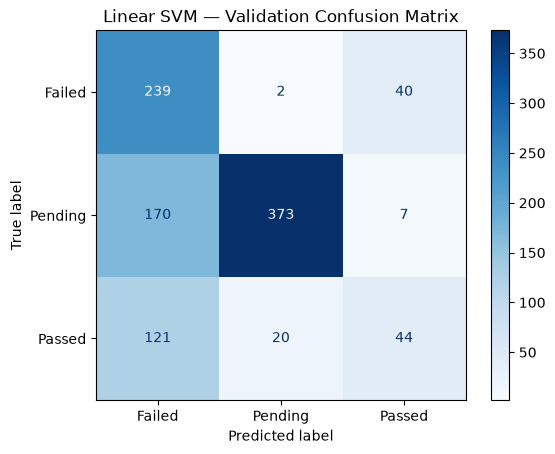

In [42]:
ConfusionMatrixDisplay.from_predictions(
    y_val,
    svm_val_meta_text_pred,
    labels=["Failed", "Pending", "Passed"],
    cmap="Blues",
    values_format="d"
)

plt.title("Linear SVM — Validation Confusion Matrix")
plt.show()

In [43]:
svm_feature_names = (
    svm__meta_text_pipeline.named_steps["preprocessor"]
    .get_feature_names_out()
)

svm_classifier = (
    svm__meta_text_pipeline.named_steps["classifier"]
)

svm_coefficients = pd.DataFrame(
    svm_classifier.coef_,
    index=svm_classifier.classes_,
    columns=svm_feature_names
)

# Features with the largest positive coefficients for Passed
svm_coefficients.loc["Passed"].nlargest(15)

text__version enacted                 2.293893
text__approved                        0.976039
text__final                           0.966152
categorical__Jurisdiction_Oregon      0.835464
categorical__measure_code_HR          0.830472
categorical__Jurisdiction_Utah        0.798713
text__enrolled                        0.798436
text__enacted                         0.757494
text__approved by                     0.756849
categorical__Jurisdiction_Arkansas    0.753120
categorical__Jurisdiction_Alabama     0.668430
categorical__measure_code_AR          0.656193
text__passed                          0.630744
text__secretary                       0.615830
text__secretary of                    0.599224
Name: Passed, dtype: float64

Clear indication from text of data leakage. Bill text includes data confirming a bill has been enacted, approved or is the final version. 

### XGBoost Models

In [44]:
#Ruse categorical transformer
xgb_categorical_transformer = clone(categorical_transformer)

# XGBoost-specific numerical preprocessing
xgb_numeric_transformer = SimpleImputer(
    strategy="constant",
    fill_value=0,
    add_indicator=True
)

# XGBoost-specific ratio preprocessing
xgb_ratio_transformer = SimpleImputer(
    strategy="constant",
    fill_value=0,
    add_indicator=True
)

# Reuse binary preprocessing
xgb_binary_transformer = clone(binary_transformer)

# Reuse TF-IDF configuration
xgb_text_transformer = clone(text_transformer)

In [45]:
# Encode target variable
label_encoder = LabelEncoder()

y_train_xgb = label_encoder.fit_transform(y_train)
y_val_xgb = label_encoder.transform(y_val)

# Check label mapping
label_mapping = dict(enumerate(label_encoder.classes_))

print("Target encoding:", label_mapping)

Target encoding: {0: 'Failed', 1: 'Passed', 2: 'Pending'}


In [46]:
def create_xgb_preprocessor(text_column=None):
    """
    Build an XGBoost preprocessing configuration.

    Parameters
    ----------
    text_column : str or None
        Text column to vectorize.
        None produces metadata-only preprocessing.
    """

    transformers = [
        (
            "categorical",
            clone(xgb_categorical_transformer),
            categorical_features
        ),
        (
            "numeric",
            clone(xgb_numeric_transformer),
            numeric_features
        ),
        (
            "ratio",
            clone(xgb_ratio_transformer),
            ratio_features
        ),
        (
            "binary",
            clone(xgb_binary_transformer),
            binary_features
        )
    ]

    if text_column is not None:
        transformers.append(
            (
                "text",
                clone(xgb_text_transformer),
                text_column
            )
        )

    return ColumnTransformer(
        transformers=transformers,
        remainder="drop",
        sparse_threshold=1.0
    )

In [47]:
def create_xgb_model():
    """Initialize an untuned multiclass XGBoost baseline."""

    return XGBClassifier(
        objective="multi:softprob",
        num_class=len(label_encoder.classes_),
        n_estimators=100,
        max_depth=3,
        learning_rate=0.1,
        subsample=1.0,
        colsample_bytree=1.0,
        min_child_weight=1,
        reg_lambda=1.0,
        tree_method="hist",
        eval_metric="mlogloss",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )


#### Meta Only

In [48]:
xgb_meta = Pipeline(steps=[
    (
        "preprocessor",
        create_xgb_preprocessor()
    ),
    (
        "classifier",
        create_xgb_model()
    )
])

# Train
xgb_meta.fit(X_train_meta, y_train_xgb)

# Predict
xgb_meta_train_pred = label_encoder.inverse_transform(
    xgb_meta.predict(X_train_meta)
)

xgb_meta_val_pred = label_encoder.inverse_transform(
    xgb_meta.predict(X_val_meta)
)


#### Meta and Summary

In [49]:
xgb_meta_summary = Pipeline(steps=[
    (
        "preprocessor",
        create_xgb_preprocessor(
            text_column="NCSL_Summary_clean"
        )
    ),
    (
        "classifier",
        create_xgb_model()
    )
])

# Prepare text
X_train_summary_xgb = X_train_meta_summary.copy()
X_val_summary_xgb = X_val_meta_summary.copy()

X_train_summary_xgb["NCSL_Summary_clean"] = (
    X_train_summary_xgb["NCSL_Summary_clean"].fillna("")
)

X_val_summary_xgb["NCSL_Summary_clean"] = (
    X_val_summary_xgb["NCSL_Summary_clean"].fillna("")
)

# Train
xgb_meta_summary.fit(
    X_train_summary_xgb,
    y_train_xgb
)

# Predict
xgb_summary_train_pred = label_encoder.inverse_transform(
    xgb_meta_summary.predict(X_train_summary_xgb)
)

xgb_summary_val_pred = label_encoder.inverse_transform(
    xgb_meta_summary.predict(X_val_summary_xgb)
)


#### Metadata and Bill Text

In [50]:

xgb_meta_text = Pipeline(steps=[
    (
        "preprocessor",
        create_xgb_preprocessor(
            text_column="Bill_Text_clean"
        )
    ),
    (
        "classifier",
        create_xgb_model()
    )
])

# Prepare text
X_train_text_xgb = X_train_meta_text.copy()
X_val_text_xgb = X_val_meta_text.copy()

X_train_text_xgb["Bill_Text_clean"] = (
    X_train_text_xgb["Bill_Text_clean"].fillna("")
)

X_val_text_xgb["Bill_Text_clean"] = (
    X_val_text_xgb["Bill_Text_clean"].fillna("")
)

# Train
xgb_meta_text.fit(
    X_train_text_xgb,
    y_train_xgb
)

# Predict
xgb_text_train_pred = label_encoder.inverse_transform(
    xgb_meta_text.predict(X_train_text_xgb)
)

xgb_text_val_pred = label_encoder.inverse_transform(
    xgb_meta_text.predict(X_val_text_xgb)
)


In [51]:
def evaluate_model(model_name, feature_set, y_train, train_pred, y_val, val_pred):
    """Evaluate classification models"""
    return {
        "Model": model_name,
        "Feature_Set": feature_set,

        "Train_Macro_F1": f1_score(
            y_train, train_pred,
            average="macro", zero_division=0
        ),

        "Val_Macro_F1": f1_score(
            y_val, val_pred,
            average="macro", zero_division=0
        ),

        "Val_Macro_Precision": precision_score(
            y_val, val_pred,
            average="macro", zero_division=0
        ),

        "Val_Macro_Recall": recall_score(
            y_val, val_pred,
            average="macro", zero_division=0
        ),

        "Val_Weighted_F1": f1_score(
            y_val, val_pred,
            average="weighted", zero_division=0
        ),

        "Val_Balanced_Accuracy": balanced_accuracy_score(
            y_val, val_pred
        ),

        "Passed_Precision": precision_score(
            y_val, val_pred,
            labels=["Passed"],
            average="macro", zero_division=0
        ),

        "Passed_Recall": recall_score(
            y_val, val_pred,
            labels=["Passed"],
            average="macro", zero_division=0
        )
    }


In [52]:
xgb_results = pd.DataFrame([
    evaluate_model(
        "XGB Metadata",
        y_train, xgb_meta_train_pred,
        y_val, xgb_meta_val_pred
    ),

    evaluate_model(
        "XGB Metadata + Summary",
        y_train, xgb_summary_train_pred,
        y_val, xgb_summary_val_pred
    ),

    evaluate_model(
        "XGB Metadata + Bill Text",
        y_train, xgb_text_train_pred,
        y_val, xgb_text_val_pred
    )
])

display(
    xgb_results.sort_values(
        "Val_Macro_F1",
        ascending=False
    ).round(4)
)

TypeError: evaluate_model() missing 1 required positional argument: 'val_pred'

### Model's Comparisons

In [ ]:
baseline_results = [
    # Logistic Regression
    evaluate_model(
        "Logistic Regression",
        "Metadata",
        y_train,
        X_train_meta_pred,
        y_val,
        y_val_meta_pred
    ),

    # Linear SVM
    evaluate_model(
        "Linear SVM",
        "Metadata",
        y_train,
        svm_train_meta_pred,
        y_val,
        svm_val_meta_pred
    ),

    # XGBoost
    evaluate_model(
        "XGBoost",
        "Metadata",
        y_train,
        xgb_meta_train_pred,
        y_val,
        xgb_meta_val_pred
    )
]

baseline_comparison = pd.DataFrame(baseline_results)

display(
    baseline_comparison.sort_values(
        "Val_Macro_F1",
        ascending=False
    ).round(4)
)


In [ ]:
# Logistic Regression — Metadata + Summary
baseline_results.append(
    evaluate_model(
        "Logistic Regression",
        "Metadata + Summary",
        y_train,
        X_train_meta_summary_pred,
        y_val,
        y_val_meta_summary_pred
    )
)

# Linear SVM — Metadata + Summary
baseline_results.append(
    evaluate_model(
        "Linear SVM",
        "Metadata + Summary",
        y_train,
        svm_train_meta_sum_pred,
        y_val,
        svm_val_meta_sum_pred
    )
)

# XGBoost — Metadata + Summary
baseline_results.append(
    evaluate_model(
        "XGBoost",
        "Metadata + Summary",
        y_train,
        xgb_summary_train_pred,
        y_val,
        xgb_summary_val_pred
    )
)

# Update comparison DataFrame
baseline_comparison = pd.DataFrame(baseline_results)

display(
    baseline_comparison.sort_values(
        ["Feature_Set", "Val_Macro_F1"],
        ascending=[True, False]
    ).round(4)
)


In [ ]:
# Logistic Regression — Metadata + Full Text
baseline_results.append(
    evaluate_model(
        "Logistic Regression",
        "Metadata + Full Text",
        y_train,
        X_train_meta_text_pred,
        y_val,
        y_val_meta_text_pred
    )
)

# Linear SVM — Metadata + Full Text
baseline_results.append(
    evaluate_model(
        "Linear SVM",
        "Metadata + Full Text",
        y_train,
        svm_train_meta_text_pred,
        y_val,
        svm_val_meta_text_pred
    )
)

# XGBoost — Metadata + Full Text
baseline_results.append(
    evaluate_model(
        "XGBoost",
        "Metadata + Full Text",
        y_train,
        xgb_text_train_pred,
        y_val,
        xgb_text_val_pred
    )
)

# Update comparison DataFrame
baseline_comparison = pd.DataFrame(baseline_results)

display(
    baseline_comparison.sort_values(
        ["Feature_Set", "Val_Macro_F1"],
        ascending=[True, False]
    ).round(4)
)


As a result of this baseline we can conclude, Linear SVM outperforms Logistic Regression and XGBoosting in addition to performance improvements when summaries or full Bill text are included. Validation Macro F1 scores continue to be very weak, and all models have very low Passed precision and recall. Before finetuning the model, it will be ideal to take another look at our source data to handle data leakage, class imbalances and temporal distribution shifts. <br/>

XGBoosting is overfitting and this could be primarily driven by data leakage given by text features. Train Macro F1 goes up almost 20 points from the metadata only sets to the models including text, while the validation macro f1 scores remain around the same levels. <br/>

Next Steps: <br/>
Consider limiting classes to only Pass/Fail<br/>
Enrich dataset with topics<br/>
Enrich dataset with bill text/summaries at introduction date <br/>
Consider random data split as a suplemmentary experiment to balance classes. <br/>